# Parte 1 - Configuración y reproducibilidad (Modelo A: LeNet-5)

## 0. Instalación
Se utiliza una RTX 5050, la cual es arquitectura Blackwell (sm_120): requiere PyTorch con CUDA 12.8+.
```bash
pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128
pip install wandb scikit-learn matplotlib seaborn pandas numpy tqdm
pip install pillow pandas
```

In [ ]:
import os
import random
from dataclasses import dataclass, field, asdict
from pathlib import Path

import numpy as np
import torch

import json
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

import time
import copy
from sklearn.metrics import f1_score, confusion_matrix, classification_report

from IPython.display import display

import shutil
import seaborn as sns


c:\Users\manuc\Downloads\Proyecto IA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Configuración global

In [ ]:
# Solo los 10 comandos autorizados
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
CLASSES = COMMANDS
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)


@dataclass
class AudioConfig:
    sample_rate: int = 16_000      # Hz, nativo de Speech Commands
    duration_s: float = 1.0        # clips de 1 s (pad con ceros / recorte)
    n_fft: int = 512               # tamaño de la FFT
    win_length: int = 400          # ventana Hann de 25 ms, centrada y rellena con ceros hasta n_fft
    hop_length: int = 160          # 10 ms -> 101 frames en 1 s
    n_mels: int = 64
    f_min: float = 20.0
    f_max: float = 8_000.0
    log_offset: float = 1e-6       # log(mel + offset)

    @property
    def n_samples(self) -> int:
        return int(self.sample_rate * self.duration_s)

    @property
    def n_frames(self) -> int:
        return 1 + self.n_samples // self.hop_length

    @property
    def input_shape(self):          # (C, H, W) = (1, mels, frames)
        return (1, self.n_mels, self.n_frames)


@dataclass
class PathConfig:
    # Para Colab: root = Path("/content/drive/MyDrive/proyecto1"). Se debe de ajustar dependiendo de la ubicación del proyecto en el sistema de archivos.
    root: Path = Path(os.environ.get("PROJECT_ROOT", r"C:\Users\manuc\Downloads\Proyecto IA"))

    @property
    def raw_dataset(self): return self.root / "speech_commands_v0.02"   # audios .wav
    @property
    def spectrograms(self): return self.root / "spectrograms"           # .npy / .pt
    @property
    def checkpoints(self): return self.root / "checkpoints" / "model_a_png"
    @property
    def results(self): return self.root / "results" / "model_a_png"

    def make_dirs(self):
        for p in (self.spectrograms, self.checkpoints, self.results):
            p.mkdir(parents=True, exist_ok=True)


@dataclass
class ExperimentConfig:
    seed: int = 42
    wandb_project: str = "voice-commands-proyecto1-png"
    wandb_entity: str | None = None
    model_name: str = "LeNet5-audio"
    audio: AudioConfig = field(default_factory=AudioConfig)


AUDIO = AudioConfig()
PATHS = PathConfig()
CFG = ExperimentConfig(audio=AUDIO)
PATHS.make_dirs()

print("Clases:", CLASSES, f"({NUM_CLASSES})")
print("Forma de entrada (C,H,W):", AUDIO.input_shape)
print("Raíz del proyecto:", PATHS.root)

Clases: ['yes', 'no', 'up', 'down', 'left', 'right', 'on', 'off', 'stop', 'go'] (10)
Forma de entrada (C,H,W): (1, 64, 101)
Raíz del proyecto: C:\Users\manuc\Downloads\Proyecto IA


## 2. Reproducibilidad

In [3]:
def seed_everything(seed: int = 42, deterministic: bool = True) -> None:
    """Fija todas las fuentes de aleatoriedad relevantes."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        torch.use_deterministic_algorithms(True, warn_only=True)


def seed_worker(worker_id: int) -> None:
    """Para DataLoader(num_workers>0): semilla distinta pero reproducible por worker."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_generator(seed: int = 42) -> torch.Generator:
    g = torch.Generator()
    g.manual_seed(seed)
    return g


seed_everything(CFG.seed)

## 3. Dispositivo y verificación de la GPU

In [4]:
def get_device(verbose: bool = True) -> torch.device:
    if not torch.cuda.is_available():
        if verbose:
            print("CUDA no disponible -> usando CPU. Revisa driver y build cu128.")
        return torch.device("cpu")

    dev = torch.device("cuda")
    if verbose:
        name = torch.cuda.get_device_name(0)
        cap = torch.cuda.get_device_capability(0)
        arch = f"sm_{cap[0]}{cap[1]}"
        print(f"GPU: {name} | capability {cap} ({arch})")
        print(f"PyTorch {torch.__version__} | CUDA runtime {torch.version.cuda}")
        print("Arquitecturas compiladas en esta build:", torch.cuda.get_arch_list())
        if arch not in torch.cuda.get_arch_list():
            print(f"AVISO: {arch} no está en la build de PyTorch. Instala la rueda cu128 o superior.")
        # Prueba real: un kernel simple en GPU
        x = torch.randn(1024, 1024, device=dev)
        _ = (x @ x).sum().item()
        print("Prueba de kernel en GPU: OK")
    return dev


DEVICE = get_device()

GPU: NVIDIA GeForce RTX 5050 | capability (12, 0) (sm_120)
PyTorch 2.11.0+cu128 | CUDA runtime 12.8
Arquitecturas compiladas en esta build: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
Prueba de kernel en GPU: OK


## 4. Weights & Biases
Se debe ejecutar `wandb login` una vez en la terminal. Cada corrida registra su config completa.

In [5]:
def init_wandb(run_name: str, dataset_variant: str, hparams: dict, tags=None):
    """dataset_variant: 'base' | 'aumentado'."""
    import wandb
    config = {
        "model": CFG.model_name,
        "dataset_variant": dataset_variant,
        "seed": CFG.seed,
        "num_classes": NUM_CLASSES,
        "classes": CLASSES,
        "audio": asdict(AUDIO),
        **hparams,
    }
    return wandb.init(
        project=CFG.wandb_project,
        entity=CFG.wandb_entity,
        name=run_name,
        group=f"modelA-{dataset_variant}",
        tags=["modelA", dataset_variant] + (tags or []),
        config=config,
        reinit="finish_previous",
    )

## 5. Contrato de entrada del modelo 

In [6]:
INPUT_CONTRACT = {
    "audio_format": "mono, WAV int16 -> float32 en [-1, 1] (dividir entre 32768)",
    "sample_rate": AUDIO.sample_rate,
    "clip_samples": AUDIO.n_samples,
    "length_fix": "recorte o relleno con ceros CENTRADO a 16000 muestras",
    "stft": {"pad": "reflect n_fft//2 a cada lado", "n_fft": AUDIO.n_fft, "hop": AUDIO.hop_length,
             "window": f"Hann periodica de {AUDIO.win_length}, centrada y rellena con ceros hasta {AUDIO.n_fft}",
             "power": 2},
    "mel": {"n_mels": AUDIO.n_mels, "f_min": AUDIO.f_min, "f_max": AUDIO.f_max,
            "scale": "HTK, filtros triangulares, sin normalizar por area"},
    "log": f"log(mel + {AUDIO.log_offset})",
    "png_step": "min-max POR CLIP a 0-255, redondeo a uint8 (los PNG se guardan con flipud; al cargar se deshace)",
    "model_input": "x/255 y luego (x - mean) / std",
    "tensor_shape_NCHW": (1, *AUDIO.input_shape),
    "normalization": "PENDIENTE (se calcula en la Parte 2 sobre train crudo)",
    "classes_order": CLASSES,
}
print(INPUT_CONTRACT)

{'audio_format': 'mono, WAV int16 -> float32 en [-1, 1] (dividir entre 32768)', 'sample_rate': 16000, 'clip_samples': 16000, 'length_fix': 'recorte o relleno con ceros CENTRADO a 16000 muestras', 'stft': {'pad': 'reflect n_fft//2 a cada lado', 'n_fft': 512, 'hop': 160, 'window': 'Hann periodica de 400, centrada y rellena con ceros hasta 512', 'power': 2}, 'mel': {'n_mels': 64, 'f_min': 20.0, 'f_max': 8000.0, 'scale': 'HTK, filtros triangulares, sin normalizar por area'}, 'log': 'log(mel + 1e-06)', 'png_step': 'min-max POR CLIP a 0-255, redondeo a uint8 (los PNG se guardan con flipud; al cargar se deshace)', 'model_input': 'x/255 y luego (x - mean) / std', 'tensor_shape_NCHW': (1, 1, 64, 101), 'normalization': 'PENDIENTE (se calcula en la Parte 2 sobre train crudo)', 'classes_order': ['yes', 'no', 'up', 'down', 'left', 'right', 'on', 'off', 'stop', 'go']}


# Parte 2 - Interfaz de datos con los PNG
Se leen los PNG que genera `preprocesamiento.ipynb` (64x101, escala de grises de 8 bits):
  data/crudo/{comando}/{archivo}.png       -> dataset crudo
  data/aumentado/{comando}/{archivo}.png   -> mismas imágenes con SpecAugment ya aplicado

Decisiones:
1. El preprocesamiento NO trae particiones: se usan las listas OFICIALES (validation_list.txt / testing_list.txt).
2. Solo 10 clases.
3. Val y test salen SIEMPRE de `crudo`: el augmentation solo se aplica a train. Así ambas variantes se
   comparan sobre los mismos datos limpios, y la evaluación refleja el uso real.
4. Los PNG se guardaron con flipud: al cargar se deshace (banda mel 0 = fila 0, igual que el resto del pipeline).
5. Normalización: x/255 y luego (x - mean)/std, con mean/std de TRAIN crudo (mismas para ambas variantes).

## 1. Rutas

In [8]:
RAW_DIR = Path(r"C:\Users\manuc\Downloads\Proyecto IA\Dataset")   # solo se usan las listas oficiales
PNG_DIR = Path(r"C:\Users\manuc\Downloads\Proyecto IA\data")      # salida de preprocesamiento.ipynb
PATHS.root = RAW_DIR.parent
PATHS.make_dirs()

for p in (RAW_DIR / "validation_list.txt", RAW_DIR / "testing_list.txt", PNG_DIR / "crudo", PNG_DIR / "aumentado"):
    assert p.exists(), f"No encuentro: {p}"
print("PNG:", PNG_DIR)
print("Resultados:", PATHS.results)

PNG: C:\Users\manuc\Downloads\Proyecto IA\data
Resultados: C:\Users\manuc\Downloads\Proyecto IA\results\model_a_png


## 2. Manifiesto con particiones oficiales

In [9]:
def _read_list(path: Path) -> set:
    return {l.strip().replace("\\", "/") for l in path.read_text().splitlines() if l.strip()}


def build_manifest() -> pd.DataFrame:
    val_set = _read_list(RAW_DIR / "validation_list.txt")
    test_set = _read_list(RAW_DIR / "testing_list.txt")
    rows = []
    for cmd in COMMANDS:
        crudo = sorted(p.name for p in (PNG_DIR / "crudo" / cmd).glob("*.png"))
        aum = sorted(p.name for p in (PNG_DIR / "aumentado" / cmd).glob("*.png"))
        assert crudo == aum, f"crudo y aumentado no tienen los mismos archivos en '{cmd}'"
        for name in crudo:
            wav = f"{cmd}/{name[:-4]}.wav"                  # nombre del WAV original en las listas oficiales
            split = "test" if wav in test_set else "val" if wav in val_set else "train"
            rows.append((cmd, name, wav, split, CLASS_TO_IDX[cmd]))
    return pd.DataFrame(rows, columns=["cmd", "file", "wav", "split", "label"])


manifest = build_manifest()
manifest.to_csv(PATHS.spectrograms / "manifest_png.csv", index=False)

# control: lo que dicen las listas oficiales para estos 10 comandos vs. lo encontrado en los PNG
for split, lst in (("val", _read_list(RAW_DIR / "validation_list.txt")), ("test", _read_list(RAW_DIR / "testing_list.txt"))):
    esperado = sum(w.split("/")[0] in COMMANDS for w in lst)
    print(f"{split}: lista oficial {esperado} | PNG {int((manifest.split == split).sum())}")

print(manifest.groupby(["split", "cmd"]).size().unstack(0).reindex(COMMANDS))

val: lista oficial 3703 | PNG 3703
test: lista oficial 4074 | PNG 4074
split  test  train  val
cmd                    
yes     419   3228  397
no      405   3130  406
up      425   2948  350
down    406   3134  377
left    412   3037  352
right   396   3019  363
on      396   3086  363
off     402   2970  373
stop    411   3111  350
go      402   3106  372


## 3. Carga de PNG a tensores (caché uint8, ~6 KB por imagen)

In [10]:
def load_png(path: Path) -> np.ndarray:
    img = np.array(Image.open(path))
    assert img.dtype == np.uint8 and img.shape == (AUDIO.n_mels, AUDIO.n_frames), (path, img.dtype, img.shape)
    return np.flipud(img).copy()          # los PNG se guardaron con flipud: se restaura la orientación


def build_cache(variant: str, split: str) -> dict:
    out = PATHS.spectrograms / f"png_{variant}_{split}.pt"
    if out.exists():
        return torch.load(out)
    d = manifest[manifest.split == split]
    xs = np.stack([load_png(PNG_DIR / variant / r.cmd / r.file)
                   for r in tqdm(d.itertuples(), total=len(d), desc=f"{variant}/{split}")])
    data = {"x": torch.from_numpy(xs).unsqueeze(1),                 # (N, 1, 64, 101) uint8
            "y": torch.tensor(d.label.values, dtype=torch.long),
            "paths": d.wav.tolist()}
    torch.save(data, out)
    return data


DATA = {
    "crudo": {s: build_cache("crudo", s) for s in ("train", "val", "test")},
    "aumentado": {"train": build_cache("aumentado", "train")},      # val/test aumentados no se usan
}
assert torch.equal(DATA["crudo"]["train"]["y"], DATA["aumentado"]["train"]["y"])
for v, d in DATA.items():
    for s, t in d.items():
        print(f"{v:9s} {s:5s}", tuple(t["x"].shape), t["x"].dtype)

crudo     train (30769, 1, 64, 101) torch.uint8
crudo     val   (3703, 1, 64, 101) torch.uint8
crudo     test  (4074, 1, 64, 101) torch.uint8
aumentado train (30769, 1, 64, 101) torch.uint8


## 4. Normalización (con TRAIN crudo; las mismas estadísticas para ambas variantes)

In [11]:
stats_path = PATHS.spectrograms / "norm_stats_png.json"
if stats_path.exists():
    stats = json.loads(stats_path.read_text())
else:
    xt = DATA["crudo"]["train"]["x"].float() / 255.0
    stats = {"mean": float(xt.mean()), "std": float(xt.std())}
    stats_path.write_text(json.dumps(stats))
MEAN, STD = stats["mean"], stats["std"]
INPUT_CONTRACT["normalization"] = f"x/255, luego (x - {MEAN:.4f}) / {STD:.4f}"
print("Normalización:", stats)

Normalización: {'mean': 0.32374921441078186, 'std': 0.23642228543758392}


## 5. Dataset y DataLoaders
`variant`: "base" (train crudo) o "aumentado" (train con SpecAugment del compañero).
Val y test siempre son crudos.

In [12]:
class SpectrogramDataset(Dataset):
    def __init__(self, x_u8, y, mean, std, transform=None):
        self.x, self.y, self.mean, self.std, self.transform = x_u8, y, mean, std, transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = (self.x[i].float() / 255.0 - self.mean) / self.std
        if self.transform is not None:
            x = self.transform(x)
        return x, self.y[i]


def make_loaders(batch_size: int = 64, train_transform=None, num_workers: int = 0, seed: int = 42,
                 variant: str = "base"):
    """num_workers=0 es lo más rápido en Windows con datos ya en memoria."""
    src = "aumentado" if variant == "aumentado" else "crudo"
    kw = dict(batch_size=batch_size, num_workers=num_workers, pin_memory=DEVICE.type == "cuda",
              worker_init_fn=seed_worker if num_workers else None)
    tr, va, te = DATA[src]["train"], DATA["crudo"]["val"], DATA["crudo"]["test"]
    return (
        DataLoader(SpectrogramDataset(tr["x"], tr["y"], MEAN, STD, train_transform),
                   shuffle=True, generator=make_generator(seed), **kw),
        DataLoader(SpectrogramDataset(va["x"], va["y"], MEAN, STD), shuffle=False, **kw),
        DataLoader(SpectrogramDataset(te["x"], te["y"], MEAN, STD), shuffle=False, **kw),
    )


train_loader, val_loader, test_loader = make_loaders(batch_size=64)

## 6. Verificaciones

Sin fuga de archivos entre particiones: OK
Batch: (64, 1, 64, 101) | media≈ 0.044 | std≈ 0.964


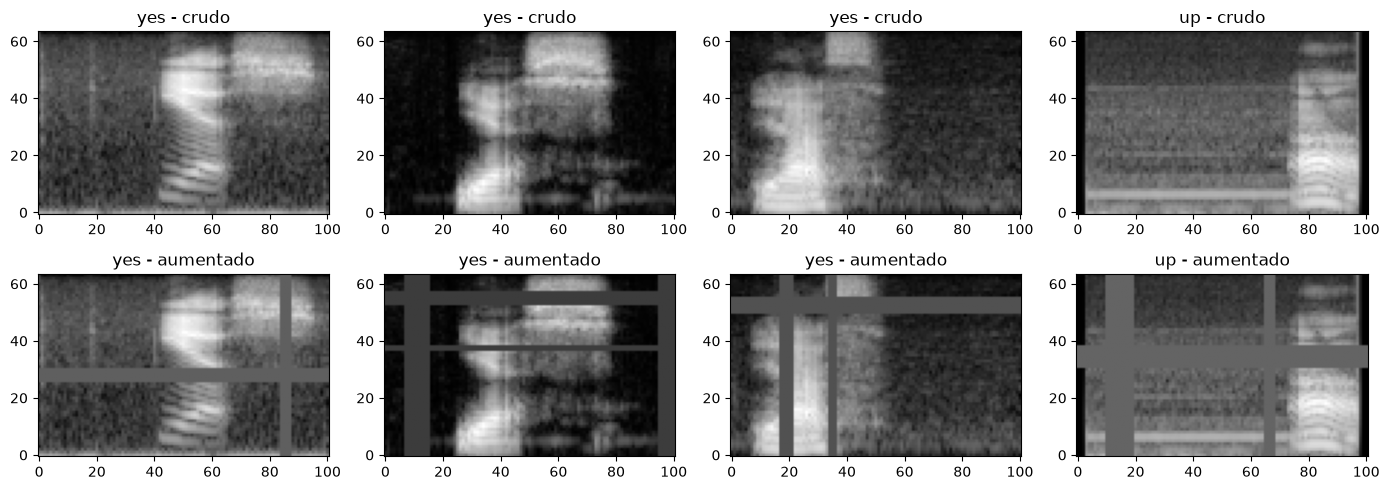

In [ ]:
# (a) ningún archivo en dos particiones
P = {s: set(manifest[manifest.split == s].wav) for s in ("train", "val", "test")}
assert not (P["train"] & P["val"]) and not (P["train"] & P["test"]) and not (P["val"] & P["test"])
print("Sin fuga de archivos entre particiones: OK")

# (b) forma y estadísticas de un batch
xb, yb = next(iter(train_loader))
print("Batch:", tuple(xb.shape), "| media≈", round(xb.mean().item(), 3), "| std≈", round(xb.std().item(), 3))

# (c) mismo clip: crudo vs aumentado y orientación correcta
fig, axs = plt.subplots(2, 4, figsize=(14, 5))
for j, i in enumerate([0, 500, 2000, 8000]):
    for r, v in enumerate(("crudo", "aumentado")):
        axs[r, j].imshow(DATA[v]["train"]["x"][i, 0].numpy(), origin="lower", aspect="auto", cmap="gray")
        axs[r, j].set_title(f"{CLASSES[DATA[v]['train']['y'][i]]} - {v}")
plt.tight_layout()
plt.savefig(PATHS.results / "ejemplos_crudo_vs_aumentado.png", dpi=200)
plt.show()

# Parte 3 - Modelo A: LeNet-5 
Solo se usan bloques de `torch.nn`.

Arquitectura clásica (LeCun et al., 1998).

| Capa | Operación | Salida (C,H,W) |
|---|---|---|
| Entrada | log-mel normalizado | 1 x 64 x 101 |
| C1 | Conv 5x5, 6 filtros, tanh | 6 x 60 x 97 |
| S2 | AvgPool 2x2 | 6 x 30 x 48 |
| C3 | Conv 5x5, 16 filtros, tanh | 16 x 26 x 44 |
| S4 | AvgPool 2x2 | 16 x 13 x 22 |
| C5 | Flatten (4576) -> Linear 120, tanh (equivale a conv con kernel del tamaño del mapa) | 120 |
| F6 | Linear 84, tanh | 84 |
| Salida | Linear 10 (logits) | 10 |


In [ ]:
class LeNet5Audio(nn.Module):
    def __init__(self, in_shape=AUDIO.input_shape, num_classes=NUM_CLASSES,
                 activation: str = "tanh", pool: str = "avg", dropout: float = 0.0):
        super().__init__()
        c = in_shape[0]
        Act = {"tanh": nn.Tanh, "relu": nn.ReLU}[activation]
        Pool = {"avg": nn.AvgPool2d, "max": nn.MaxPool2d}[pool]

        self.features = nn.Sequential(
            nn.Conv2d(c, 6, kernel_size=5), Act(), Pool(2),     # C1, S2
            nn.Conv2d(6, 16, kernel_size=5), Act(), Pool(2),    # C3, S4
        )
        with torch.no_grad():                                   # evita calcular a mano la dimensión aplanada
            n_flat = self.features(torch.zeros(1, *in_shape)).numel()
        self.n_flat = n_flat

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_flat, 120), Act(), nn.Dropout(dropout),  # C5
            nn.Linear(120, 84), Act(), nn.Dropout(dropout),      # F6
            nn.Linear(84, num_classes),                          # logits (CrossEntropyLoss aplica softmax)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def trace_shapes(model: nn.Module, in_shape=AUDIO.input_shape):
    """Imprime la forma de salida y los parámetros de cada capa."""
    model = model.eval().cpu()
    x = torch.zeros(1, *in_shape)
    rows = []
    with torch.no_grad():
        for seq in (model.features, model.classifier):
            for layer in seq:
                x = layer(x)
                rows.append((layer.__class__.__name__, tuple(x.shape[1:]),
                             sum(p.numel() for p in layer.parameters())))
    print(f"{'Capa':<12}{'Salida':<20}{'Parámetros':>12}")
    for n, s, p in rows:
        print(f"{n:<12}{str(s):<20}{p:>12,}")
    print(f"{'TOTAL':<32}{count_params(model):>12,}")
    return rows

## Verificaciones

In [15]:
model_test = LeNet5Audio()
rows = trace_shapes(model_test)
print("Dimensión aplanada:", model_test.n_flat)

# la salida debe ser (batch, 10)
out = model_test(torch.zeros(4, *AUDIO.input_shape))
assert out.shape == (4, NUM_CLASSES), out.shape
print("Salida del modelo:", tuple(out.shape), "OK")

# Hallazgo para el informe: C5 concentra casi todos los parámetros.
f5 = model_test.n_flat * 120 + 120
print(f"C5 = {f5:,} parámetros ({100 * f5 / count_params(model_test):.1f} % del total)")

Capa        Salida                Parámetros
Conv2d      (6, 60, 97)                  156
Tanh        (6, 60, 97)                    0
AvgPool2d   (6, 30, 48)                    0
Conv2d      (16, 26, 44)               2,416
Tanh        (16, 26, 44)                   0
AvgPool2d   (16, 13, 22)                   0
Flatten     (4576,)                        0
Linear      (120,)                   549,240
Tanh        (120,)                         0
Dropout     (120,)                         0
Linear      (84,)                     10,164
Tanh        (84,)                          0
Dropout     (84,)                          0
Linear      (10,)                        850
TOTAL                                562,826
Dimensión aplanada: 4576
Salida del modelo: (4, 10) OK
C5 = 549,240 parámetros (97.6 % del total)


## Diagrama de la arquitectura

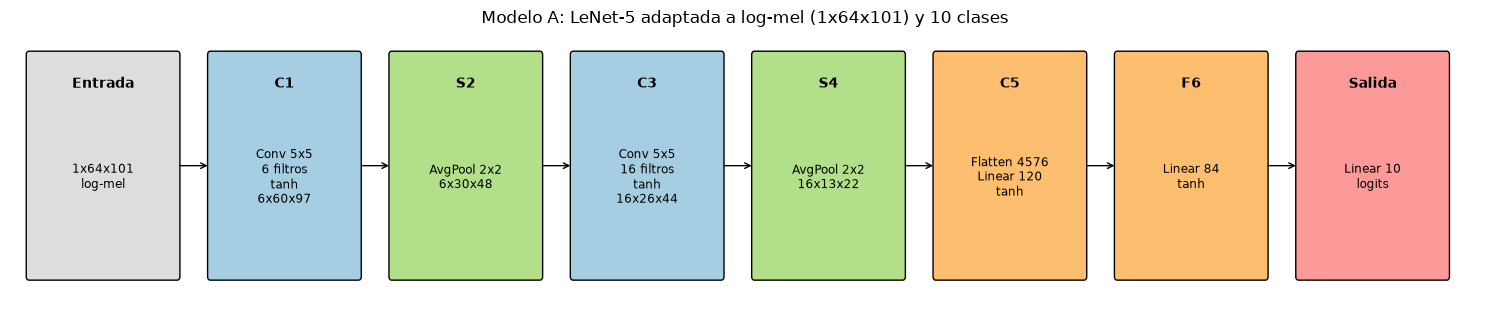

In [16]:
def draw_lenet_diagram(save_path=None):
    blocks = [
        ("Entrada", "1x64x101\nlog-mel"),
        ("C1", "Conv 5x5\n6 filtros\ntanh\n6x60x97"),
        ("S2", "AvgPool 2x2\n6x30x48"),
        ("C3", "Conv 5x5\n16 filtros\ntanh\n16x26x44"),
        ("S4", "AvgPool 2x2\n16x13x22"),
        ("C5", "Flatten 4576\nLinear 120\ntanh"),
        ("F6", "Linear 84\ntanh"),
        ("Salida", f"Linear {NUM_CLASSES}\nlogits"),
    ]
    colors = {"Entrada": "#dddddd", "C1": "#a6cee3", "S2": "#b2df8a", "C3": "#a6cee3",
              "S4": "#b2df8a", "C5": "#fdbf6f", "F6": "#fdbf6f", "Salida": "#fb9a99"}
    fig, ax = plt.subplots(figsize=(15, 3.2))
    w, gap = 1.55, 0.35
    for i, (name, desc) in enumerate(blocks):
        x0 = i * (w + gap)
        ax.add_patch(FancyBboxPatch((x0, 0.2), w, 1.9, boxstyle="round,pad=0.03",
                                    fc=colors[name], ec="black"))
        ax.text(x0 + w / 2, 1.85, name, ha="center", va="center", fontweight="bold")
        ax.text(x0 + w / 2, 1.05, desc, ha="center", va="center", fontsize=8.5)
        if i < len(blocks) - 1:
            ax.annotate("", xy=(x0 + w + gap, 1.15), xytext=(x0 + w, 1.15),
                        arrowprops=dict(arrowstyle="->"))
    ax.set_xlim(-0.2, len(blocks) * (w + gap))
    ax.set_ylim(0, 2.3)
    ax.axis("off")
    ax.set_title("Modelo A: LeNet-5 adaptada a log-mel (1x64x101) y 10 clases")
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()


draw_lenet_diagram(PATHS.results / "lenet5_diagram.png")

# Parte 4 - Entrenamiento, validación y test (Modelo A)

Decisiones de diseño:
- Pérdida: CrossEntropyLoss (clasificación multiclase sobre logits).
- Optimizador: Adam / AdamW / SGD con momentum, configurable por hiperparámetros.
- Selección del mejor epoch y early stopping: por F1 macro en VALIDACIÓN.
- El conjunto de TEST no se toca durante el entrenamiento: solo se evalúa al final,
  sobre el checkpoint elegido (evita sesgo de selección).

Antes de la primera corrida, en la terminal con el .venv activo:  wandb login

## 1. Construcción de optimizador y scheduler

In [18]:
def build_optimizer(model: nn.Module, hp: dict):
    name = hp.get("optimizer", "adam").lower()
    wd = hp.get("weight_decay", 0.0)
    if name == "adam":
        return torch.optim.Adam(model.parameters(), lr=hp["lr"], weight_decay=wd)
    if name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=wd)
    if name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=hp["lr"], momentum=hp.get("momentum", 0.9),
                               weight_decay=wd)
    raise ValueError(f"Optimizador desconocido: {name}")


def build_scheduler(optimizer, hp: dict):
    s = hp.get("scheduler", "none").lower()
    if s == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=hp["epochs"])
    if s == "plateau":   # se actualiza con el F1 de validación
        return torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    return None

## 2. Una época de entrenamiento y evaluación

In [19]:
def train_one_epoch(model, loader, criterion, optimizer, device=DEVICE):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, device=DEVICE):
    """Devuelve loss (CE sin label smoothing), accuracy, F1 macro y los vectores y_true / y_pred."""
    model.eval()
    ce = nn.CrossEntropyLoss(reduction="sum")
    total_loss, n = 0.0, 0
    ys, ps = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        logits = model(x)
        total_loss += ce(logits, y).item()
        n += y.size(0)
        ys.append(y.cpu())
        ps.append(logits.argmax(1).cpu())
    y_true, y_pred = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {
        "loss": total_loss / n,
        "acc": float((y_true == y_pred).mean()),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", labels=list(range(NUM_CLASSES)),
                                   zero_division=0)),
        "y_true": y_true,
        "y_pred": y_pred,
    }

## 3. Experimento completo (una corrida = una combinación de hiperparámetros)

In [20]:
def model_kwargs(hp: dict) -> dict:
    return dict(activation=hp.get("activation", "tanh"), pool=hp.get("pool", "avg"),
                dropout=hp.get("dropout", 0.0))


def run_experiment(run_name: str, hp: dict, dataset_variant: str, train_transform=None,
                   use_wandb: bool = True) -> dict:
    """
    hp: lr, batch_size, epochs, optimizer, weight_decay, [momentum, scheduler, patience, label_smoothing,
        activation, pool, dropout, seed]
    dataset_variant: 'base' | 'aumentado'
    train_transform: gancho opcional (None). El augmentation viene en los PNG de la variante 'aumentado'.
    """
    seed = hp.get("seed", CFG.seed)
    seed_everything(seed)

    train_loader, val_loader, _ = make_loaders(hp["batch_size"], train_transform, seed=seed,
                                               variant=dataset_variant)
    model = LeNet5Audio(**model_kwargs(hp)).to(DEVICE)
    criterion = nn.CrossEntropyLoss(label_smoothing=hp.get("label_smoothing", 0.0))
    optimizer = build_optimizer(model, hp)
    scheduler = build_scheduler(optimizer, hp)
    patience = hp.get("patience", 8)

    run = None
    if use_wandb:
        import wandb
        run = init_wandb(run_name, dataset_variant, {**hp, "n_params": count_params(model)})

    ckpt_path = PATHS.checkpoints / f"{run_name}.pt"
    best = {"f1_macro": -1.0}
    best_y = None
    bad_epochs = 0
    history = []
    t0 = time.time()

    for epoch in range(1, hp["epochs"] + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val = evaluate(model, val_loader)
        lr = optimizer.param_groups[0]["lr"]

        if scheduler is not None:
            scheduler.step(val["f1_macro"]) if hp.get("scheduler") == "plateau" else scheduler.step()

        row = {"epoch": epoch, "lr": lr,
               "train_loss": tr_loss, "train_acc": tr_acc,
               "val_loss": val["loss"], "val_acc": val["acc"], "val_f1_macro": val["f1_macro"],
               "gap_acc": tr_acc - val["acc"], "gap_loss": val["loss"] - tr_loss}
        history.append(row)
        if run is not None:
            run.log(row)

        print(f"[{run_name}] ep {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {val['loss']:.4f} acc {val['acc']:.4f} f1 {val['f1_macro']:.4f}")

        if val["f1_macro"] > best["f1_macro"]:
            best = {"epoch": epoch, "f1_macro": val["f1_macro"], "acc": val["acc"], "loss": val["loss"]}
            best_y = (val["y_true"], val["y_pred"])
            bad_epochs = 0
            torch.save({
                "model_state": copy.deepcopy(model.state_dict()),
                "model_kwargs": model_kwargs(hp),
                "hparams": hp,
                "dataset_variant": dataset_variant,
                "best_val": best,
                "norm": {"mean": MEAN, "std": STD},
                "classes": CLASSES,
                "input_shape": AUDIO.input_shape,
                "audio_config": asdict(AUDIO),
            }, ckpt_path)
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"[{run_name}] early stopping en la época {epoch} (mejor: {best['epoch']})")
                break

    elapsed = time.time() - t0
    summary = {"run_name": run_name, "dataset_variant": dataset_variant, "hparams": hp,
               "n_params": count_params(model), "epochs_run": len(history),
               "best_epoch": best["epoch"], "val_f1_macro": best["f1_macro"],
               "val_acc": best["acc"], "val_loss": best["loss"],
               "final_train_acc": history[-1]["train_acc"], "train_time_s": elapsed,
               "ckpt": str(ckpt_path)}

    if run is not None:
        import wandb
        run.summary.update({k: v for k, v in summary.items() if k not in ("hparams",)})
        run.log({"val/confusion_matrix": wandb.plot.confusion_matrix(
            y_true=best_y[0].tolist(), preds=best_y[1].tolist(), class_names=CLASSES)})
        run.finish()

    (PATHS.results / f"{run_name}_history.json").write_text(json.dumps({"summary": summary, "history": history}, indent=2))
    return summary

## 4. Evaluación en TEST de un checkpoint

In [21]:
def evaluate_checkpoint(ckpt_path, split: str = "test", batch_size: int = 128, use_wandb_run=None):
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)  # checkpoint propio
    model = LeNet5Audio(**ckpt["model_kwargs"]).to(DEVICE)
    model.load_state_dict(ckpt["model_state"])
    _, val_loader, test_loader = make_loaders(batch_size)
    loader = test_loader if split == "test" else val_loader
    res = evaluate(model, loader)
    print(f"{split.upper()} | loss {res['loss']:.4f} | acc {res['acc']:.4f} | F1 macro {res['f1_macro']:.4f}")
    print(classification_report(res["y_true"], res["y_pred"], target_names=CLASSES, digits=4, zero_division=0))
    res["confusion_matrix"] = confusion_matrix(res["y_true"], res["y_pred"], labels=list(range(NUM_CLASSES)))
    return res

## 5. Prueba rápida: 2 épocas, sin W&B

In [22]:
smoke_hp = {"lr": 1e-3, "batch_size": 64, "epochs": 2, "optimizer": "adam", "weight_decay": 0.0}
smoke = run_experiment("smoke_test", smoke_hp, "base", use_wandb=False)
print({k: smoke[k] for k in ("val_f1_macro", "val_acc", "n_params", "train_time_s")})

# Reproducibilidad: dos corridas con la misma semilla deben dar (casi) lo mismo
smoke2 = run_experiment("smoke_test_2", smoke_hp, "base", use_wandb=False)
print("Diferencia val F1 entre corridas:", abs(smoke["val_f1_macro"] - smoke2["val_f1_macro"]))

[smoke_test] ep 01 | train loss 1.1658 acc 0.6085 | val loss 0.7797 acc 0.7418 f1 0.7416
[smoke_test] ep 02 | train loss 0.6451 acc 0.7810 | val loss 0.5890 acc 0.8053 f1 0.8051
{'val_f1_macro': 0.8050673028723585, 'val_acc': 0.8052930056710775, 'n_params': 562826, 'train_time_s': 23.085591077804565}
[smoke_test_2] ep 01 | train loss 1.1658 acc 0.6085 | val loss 0.7797 acc 0.7418 f1 0.7416
[smoke_test_2] ep 02 | train loss 0.6451 acc 0.7810 | val loss 0.5890 acc 0.8053 f1 0.8051
Diferencia val F1 entre corridas: 0.0


# Parte 5 - Experimentos del Modelo A
6 corridas = {Base, Aumentado} x 3 configuraciones de hiperparámetros.

- **Base** entrena con los PNG de `data/crudo`.
- **Aumentado** entrena con los PNG de `data/aumentado` (SpecAugment del compañero: 2 máscaras de frecuencia
  de hasta 8 bandas y 2 de tiempo de hasta 10 cuadros, rellenas con la media; una versión fija por imagen).
- Val y test son SIEMPRE los mismos (crudos y limpios) en ambas variantes: la comparación es justa.

## Configuraciones de hiperparámetros (3)
Solo se varían hiperparámetros.

| Cfg | Optimizador | LR | Batch | Weight decay | Scheduler | Idea |
|---|---|---|---|---|---|---|
| 1 | Adam | 1e-3 | 64 | 0 | - | referencia estándar |
| 2 | AdamW | 1e-3 | 128 | 1e-2 | coseno | regularización explícita (C5 tiene 549 mil parámetros) |
| 3 | SGD+momentum 0.9 | 2e-2 | 64 | 5e-4 | coseno | optimizador clásico de LeNet, más ruido de gradiente |

In [ ]:
EPOCHS = 40
CONFIGS = {
    "cfg1": {"optimizer": "adam",  "lr": 1e-3, "batch_size": 64,  "weight_decay": 0.0,  "scheduler": "none"},
    "cfg2": {"optimizer": "adamw", "lr": 1e-3, "batch_size": 128, "weight_decay": 1e-2, "scheduler": "cosine"},
    "cfg3": {"optimizer": "sgd",   "lr": 2e-2, "batch_size": 64,  "weight_decay": 5e-4, "scheduler": "cosine",
             "momentum": 0.9},
}
for c in CONFIGS.values():
    c.update({"epochs": EPOCHS, "patience": 8, "seed": CFG.seed})

USE_WANDB = True       

## Ejecución de las 6 corridas

In [ ]:
VARIANTS = {"base": None, "aumentado": None}  
all_results = []

for variant, transform in VARIANTS.items():
    for cfg_name, hp in CONFIGS.items():
        run_name = f"A_{variant}_{cfg_name}"
        hist_file = PATHS.results / f"{run_name}_history.json"
        if hist_file.exists():
            print(f"[{run_name}] ya existe, se carga del disco.")
            all_results.append(json.loads(hist_file.read_text())["summary"])
            continue
        all_results.append(run_experiment(run_name, hp, variant, train_transform=transform,
                                          use_wandb=USE_WANDB))

[A_base_cfg1] ya existe, se carga del disco.
[A_base_cfg2] ya existe, se carga del disco.
[A_base_cfg3] ya existe, se carga del disco.
[A_aumentado_cfg1] ya existe, se carga del disco.
[A_aumentado_cfg2] ya existe, se carga del disco.
[A_aumentado_cfg3] ya existe, se carga del disco.


## Tabla de resultados de las 6 corridas (validación) y mejor de cada variante

In [25]:
df = pd.DataFrame([{
    "run": r["run_name"], "variante": r["dataset_variant"],
    "optimizer": r["hparams"]["optimizer"], "lr": r["hparams"]["lr"],
    "batch": r["hparams"]["batch_size"], "wd": r["hparams"]["weight_decay"],
    "épocas": r["epochs_run"], "mejor_ep": r["best_epoch"],
    "train_acc_final": round(r["final_train_acc"], 4),
    "val_acc": round(r["val_acc"], 4), "val_f1": round(r["val_f1_macro"], 4),
    "val_loss": round(r["val_loss"], 4), "tiempo_s": round(r["train_time_s"], 1),
} for r in all_results])
df.to_csv(PATHS.results / "resultados_modelo_A.csv", index=False)
display(df)

best_by_variant = {v: max((r for r in all_results if r["dataset_variant"] == v),
                          key=lambda r: r["val_f1_macro"]) for v in VARIANTS}
for v, r in best_by_variant.items():
    print(f"Mejor A/{v}: {r['run_name']} | val F1 {r['val_f1_macro']:.4f} | ckpt {r['ckpt']}")

,run,variante,optimizer,lr,batch,wd,épocas,mejor_ep,train_acc_final,val_acc,val_f1,val_loss,tiempo_s
0,A_base_cfg1,base,adam,0.001,64,0.0000,15,7,0.9722,0.8412,0.8413,0.5028,62.4
1,A_base_cfg2,base,adamw,0.001,128,0.0100,26,18,1.0000,0.8490,0.8490,0.6913,94.6
2,A_base_cfg3,base,sgd,0.020,64,0.0005,39,31,1.0000,0.8863,0.8864,0.4071,163.6
3,A_aumentado_cfg1,aumentado,adam,0.001,64,0.0000,18,10,0.9661,0.8137,0.8139,0.6743,76.3
4,A_aumentado_cfg2,aumentado,adamw,0.001,128,0.0100,26,18,1.0000,0.8234,0.8227,0.8252,94.7
5,A_aumentado_cfg3,aumentado,sgd,0.020,64,0.0005,35,27,1.0000,0.8650,0.8651,0.5621,144.6


Mejor A/base: A_base_cfg3 | val F1 0.8864 | ckpt C:\Users\manuc\Downloads\Proyecto IA\checkpoints\model_a_png\A_base_cfg3.pt
Mejor A/aumentado: A_aumentado_cfg3 | val F1 0.8651 | ckpt C:\Users\manuc\Downloads\Proyecto IA\checkpoints\model_a_png\A_aumentado_cfg3.pt


# Parte 6 - Evaluación y selección del mejor Modelo A

## 1. Carga de todas las corridas

In [28]:
runs = {}
for f in sorted(PATHS.results.glob("A_*_history.json")):
    d = json.loads(f.read_text())
    runs[d["summary"]["run_name"]] = d
print(len(runs), "corridas:", list(runs))

6 corridas: ['A_aumentado_cfg1', 'A_aumentado_cfg2', 'A_aumentado_cfg3', 'A_base_cfg1', 'A_base_cfg2', 'A_base_cfg3']


## 2. Curvas de entrenamiento / validación

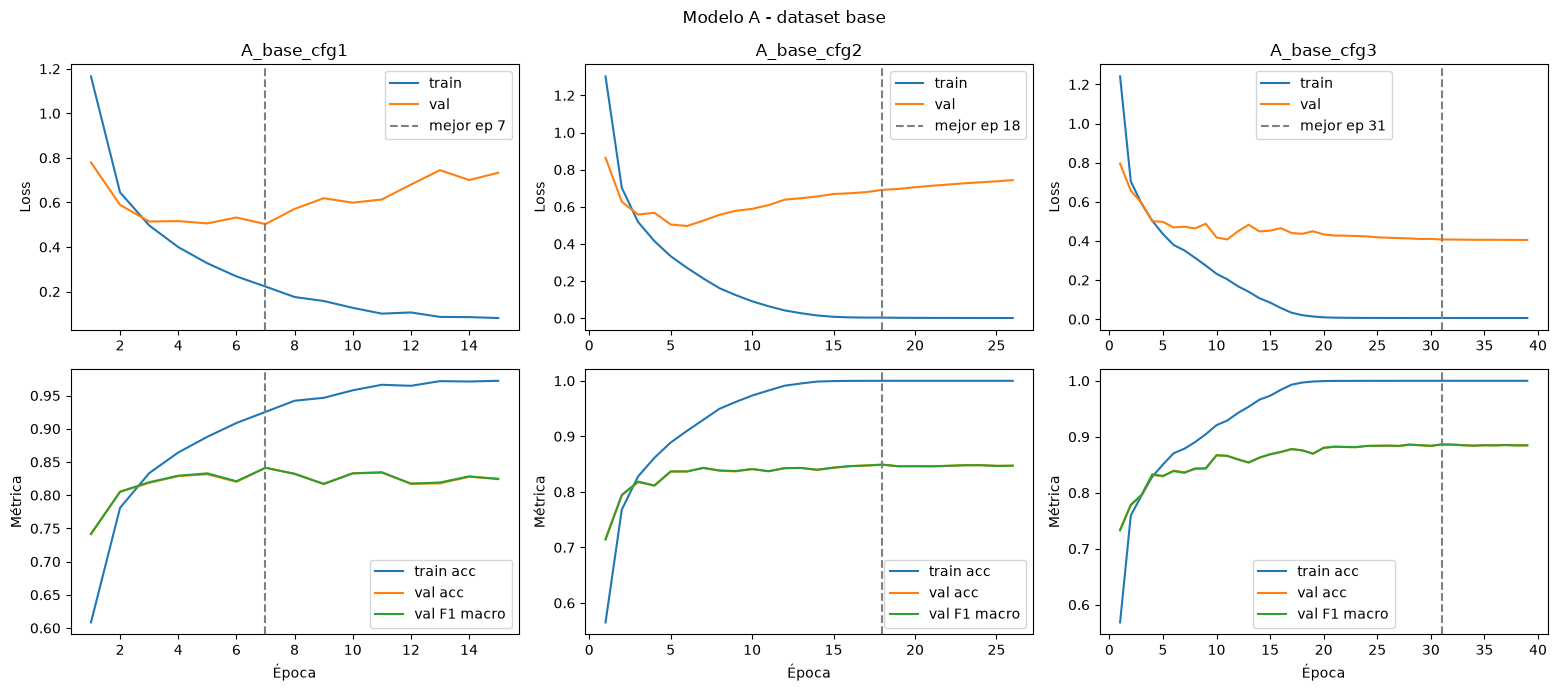

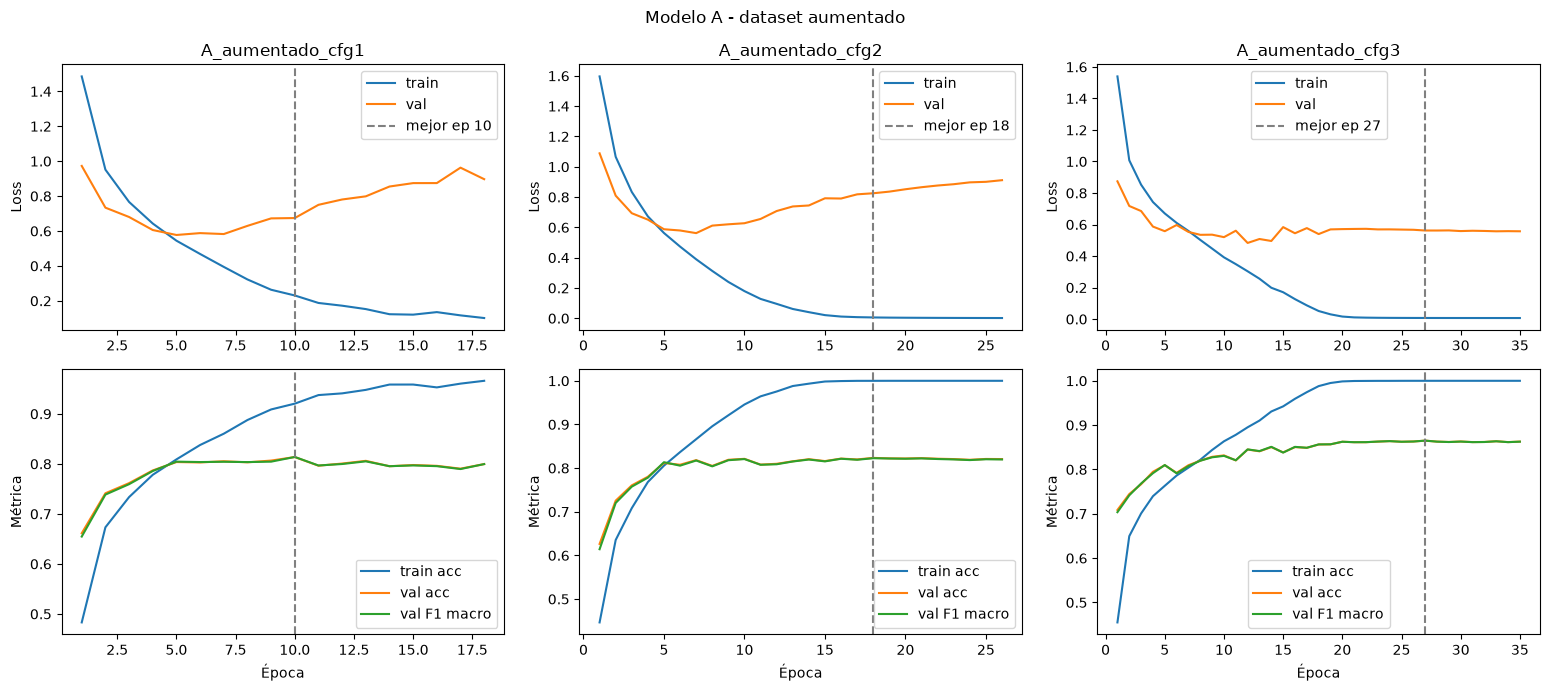

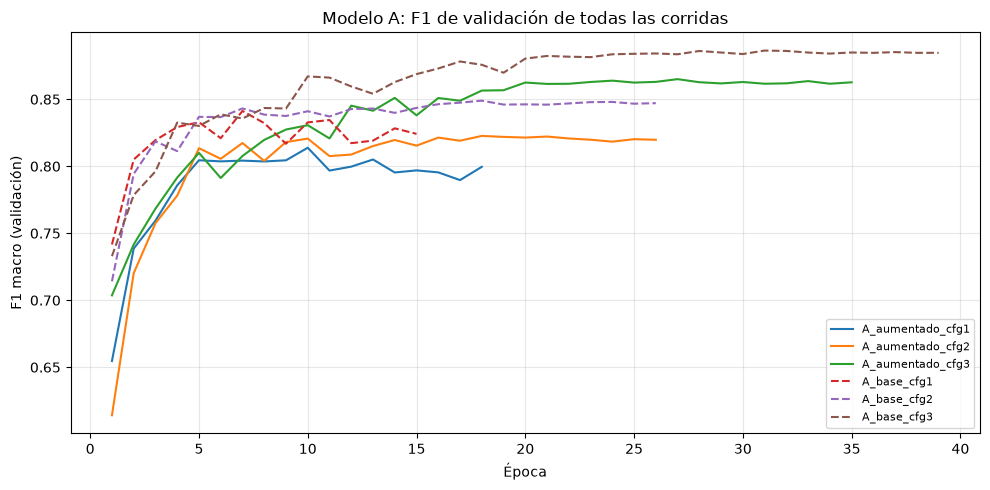

In [29]:
def plot_variant_curves(variant):
    names = [n for n in runs if runs[n]["summary"]["dataset_variant"] == variant]
    fig, axs = plt.subplots(2, len(names), figsize=(5.2 * len(names), 7), squeeze=False)
    for j, n in enumerate(names):
        h = pd.DataFrame(runs[n]["history"])
        be = runs[n]["summary"]["best_epoch"]
        axs[0, j].plot(h.epoch, h.train_loss, label="train")
        axs[0, j].plot(h.epoch, h.val_loss, label="val")
        axs[0, j].axvline(be, ls="--", c="gray", label=f"mejor ep {be}")
        axs[0, j].set_title(n); axs[0, j].set_ylabel("Loss"); axs[0, j].legend()
        axs[1, j].plot(h.epoch, h.train_acc, label="train acc")
        axs[1, j].plot(h.epoch, h.val_acc, label="val acc")
        axs[1, j].plot(h.epoch, h.val_f1_macro, label="val F1 macro")
        axs[1, j].axvline(be, ls="--", c="gray")
        axs[1, j].set_xlabel("Época"); axs[1, j].set_ylabel("Métrica"); axs[1, j].legend()
    fig.suptitle(f"Modelo A - dataset {variant}")
    plt.tight_layout()
    fig.savefig(PATHS.results / f"curvas_{variant}.png", dpi=200)
    plt.show()


for v in ("base", "aumentado"):
    plot_variant_curves(v)

# comparación de todas las corridas en una sola gráfica (F1 de validación)
fig, ax = plt.subplots(figsize=(10, 5))
for n, d in runs.items():
    h = pd.DataFrame(d["history"])
    ax.plot(h.epoch, h.val_f1_macro, ls="-" if d["summary"]["dataset_variant"] == "aumentado" else "--", label=n)
ax.set_xlabel("Época"); ax.set_ylabel("F1 macro (validación)"); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_title("Modelo A: F1 de validación de todas las corridas")
plt.tight_layout(); fig.savefig(PATHS.results / "val_f1_todas.png", dpi=200); plt.show()

## 3. Diagnóstico de overfitting / underfitting 
- Sobreajuste: train_acc - val_acc > 0.08 en el mejor epoch, o la val_loss sube > 0.05 sobre su mínimo.
- No convergió / posible subajuste: corrió todas las épocas y el mejor epoch está en las últimas 2,
  o train_acc y val_acc < 0.85.

In [30]:
def diagnose(h: pd.DataFrame, max_ep: int):
    b = h.loc[h.val_f1_macro.idxmax()]
    gap = b.train_acc - b.val_acc
    notes = []
    if gap > 0.08:
        notes.append("sobreajuste")
    if h.val_loss.iloc[-1] - h.val_loss.min() > 0.05:
        notes.append("val_loss sube tras su mínimo")
    if len(h) == max_ep and int(b.epoch) >= max_ep - 2:
        notes.append("no convergió (aún mejoraba)")
    if b.train_acc < 0.85 and b.val_acc < 0.85:
        notes.append("posible subajuste")
    return gap, notes or ["ajuste razonable"]


rows = []
for n, d in runs.items():
    h = pd.DataFrame(d["history"]); s = d["summary"]
    gap, notes = diagnose(h, s["hparams"]["epochs"])
    rows.append({"run": n, "mejor_ep": s["best_epoch"], "épocas": s["epochs_run"],
                 "train_acc@mejor": round(float(h.loc[s["best_epoch"] - 1, "train_acc"]), 4),
                 "val_acc": round(s["val_acc"], 4), "val_f1": round(s["val_f1_macro"], 4),
                 "brecha": round(gap, 4), "diagnóstico": "; ".join(notes)})
diag = pd.DataFrame(rows)
diag.to_csv(PATHS.results / "diagnostico_modelo_A.csv", index=False)
display(diag)

,run,mejor_ep,épocas,train_acc@mejor,val_acc,val_f1,brecha,diagnóstico
0,A_aumentado_cfg1,10,18,0.9204,0.8137,0.8139,0.1068,sobreajuste; val_loss sube tras su mínimo
1,A_aumentado_cfg2,18,26,0.9999,0.8234,0.8227,0.1765,sobreajuste; val_loss sube tras su mínimo
2,A_aumentado_cfg3,27,35,1.0000,0.8650,0.8651,0.1350,sobreajuste; val_loss sube tras su mínimo
3,A_base_cfg1,7,15,0.9254,0.8412,0.8413,0.0842,sobreajuste; val_loss sube tras su mínimo
4,A_base_cfg2,18,26,1.0000,0.8490,0.8490,0.1509,sobreajuste; val_loss sube tras su mínimo
5,A_base_cfg3,31,39,1.0000,0.8863,0.8864,0.1137,sobreajuste


## 4. Selección por VALIDACIÓN (F1 macro) del mejor de cada variante

In [31]:
best_by_variant = {}
for v in ("base", "aumentado"):
    cand = [d["summary"] for d in runs.values() if d["summary"]["dataset_variant"] == v]
    best_by_variant[v] = max(cand, key=lambda s: s["val_f1_macro"])
    print(f"Mejor A/{v}: {best_by_variant[v]['run_name']} | val F1 {best_by_variant[v]['val_f1_macro']:.4f}")

Mejor A/base: A_base_cfg3 | val F1 0.8864
Mejor A/aumentado: A_aumentado_cfg3 | val F1 0.8651


## 5. Evaluación en TEST de los dos mejores

A/base  (A_base_cfg3)
TEST | loss 0.4916 | acc 0.8746 | F1 macro 0.8743
              precision    recall  f1-score   support

         yes     0.9409    0.9499    0.9454       419
          no     0.8089    0.8568    0.8321       405
          up     0.8402    0.8659    0.8528       425
        down     0.8601    0.8325    0.8461       406
        left     0.8947    0.8665    0.8804       412
       right     0.9165    0.9141    0.9153       396
          on     0.8759    0.9091    0.8922       396
         off     0.8806    0.8259    0.8524       402
        stop     0.9111    0.9221    0.9166       411
          go     0.8193    0.8010    0.8101       402

    accuracy                         0.8746      4074
   macro avg     0.8748    0.8744    0.8743      4074
weighted avg     0.8749    0.8746    0.8745      4074



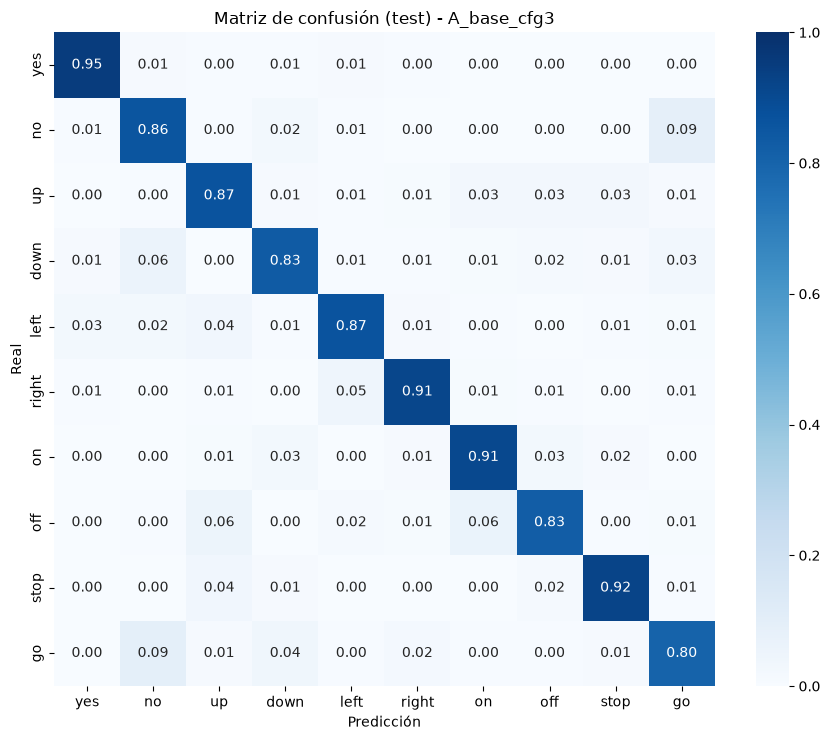

Confusiones más frecuentes (real -> predicho): [('go', 'no', 38), ('no', 'go', 37), ('off', 'on', 26), ('down', 'no', 25), ('off', 'up', 23)]
A/aumentado  (A_aumentado_cfg3)
TEST | loss 0.5917 | acc 0.8527 | F1 macro 0.8527
              precision    recall  f1-score   support

         yes     0.9282    0.9260    0.9271       419
          no     0.7242    0.8494    0.7818       405
          up     0.8640    0.8071    0.8345       425
        down     0.8297    0.8399    0.8348       406
        left     0.8872    0.8398    0.8628       412
       right     0.8900    0.8990    0.8945       396
          on     0.8449    0.8939    0.8687       396
         off     0.8805    0.8433    0.8615       402
        stop     0.9282    0.9124    0.9202       411
          go     0.7680    0.7164    0.7413       402

    accuracy                         0.8527      4074
   macro avg     0.8545    0.8527    0.8527      4074
weighted avg     0.8549    0.8527    0.8530      4074



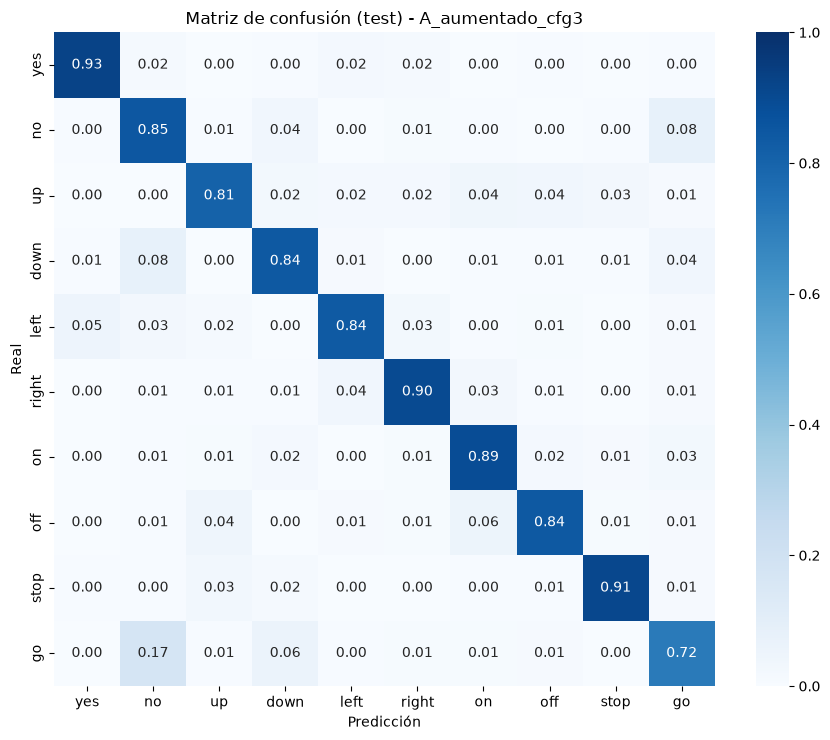

Confusiones más frecuentes (real -> predicho): [('go', 'no', 70), ('down', 'no', 32), ('no', 'go', 32), ('go', 'down', 24), ('off', 'on', 23)]


,modelo,run,val_f1,test_acc,test_f1_macro,test_loss,n_params
0,A/base,A_base_cfg3,0.8864,0.8746,0.8743,0.4916,562826
1,A/aumentado,A_aumentado_cfg3,0.8651,0.8527,0.8527,0.5917,562826


In [32]:
def plot_cm(cm, title, path):
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(9, 7.5))
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); ax.set_title(title)
    plt.tight_layout(); fig.savefig(path, dpi=200); plt.show()
    return fig


test_results, cm_figs = {}, {}
for v, s in best_by_variant.items():
    print("=" * 70, f"\nA/{v}  ({s['run_name']})")
    res = evaluate_checkpoint(s["ckpt"], split="test")
    test_results[v] = res
    cm_figs[v] = plot_cm(res["confusion_matrix"], f"Matriz de confusión (test) - {s['run_name']}",
                         PATHS.results / f"cm_test_{s['run_name']}.png")
    off = res["confusion_matrix"].copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
    print("Confusiones más frecuentes (real -> predicho):",
          [(CLASSES[i], CLASSES[j], int(off[i, j])) for i, j in top])

summary_test = pd.DataFrame([{
    "modelo": f"A/{v}", "run": best_by_variant[v]["run_name"],
    "val_f1": round(best_by_variant[v]["val_f1_macro"], 4),
    "test_acc": round(test_results[v]["acc"], 4), "test_f1_macro": round(test_results[v]["f1_macro"], 4),
    "test_loss": round(test_results[v]["loss"], 4), "n_params": best_by_variant[v]["n_params"],
} for v in best_by_variant])
summary_test.to_csv(PATHS.results / "resumen_test_modelo_A.csv", index=False)
display(summary_test)

## 6. Mejor Modelo A (criterio: F1 macro de validación) y entrega para ONNX

In [33]:
best_variant = max(best_by_variant, key=lambda v: best_by_variant[v]["val_f1_macro"])
best = best_by_variant[best_variant]
final_ckpt = PATHS.checkpoints / "best_model_A.pt"
shutil.copy(best["ckpt"], final_ckpt)
(PATHS.results / "best_model_A.json").write_text(json.dumps({
    "run_name": best["run_name"], "dataset_variant": best_variant, "hparams": best["hparams"],
    "val_f1_macro": best["val_f1_macro"], "test_f1_macro": test_results[best_variant]["f1_macro"],
    "test_acc": test_results[best_variant]["acc"], "checkpoint": str(final_ckpt),
    "classes": CLASSES, "input_shape": AUDIO.input_shape, "norm": {"mean": MEAN, "std": STD},
}, indent=2))
print(f"Mejor Modelo A: {best['run_name']} -> {final_ckpt}")

# Eficiencia (relevante para el caso de uso móvil): latencia en CPU con 1 hilo, tamaño en disco
m = LeNet5Audio(**torch.load(final_ckpt, weights_only=False)["model_kwargs"]).eval()
m.load_state_dict(torch.load(final_ckpt, weights_only=False)["model_state"])
m = m.cpu(); torch.set_num_threads(1)
x1 = torch.zeros(1, *AUDIO.input_shape)
with torch.no_grad():
    for _ in range(20): m(x1)
    t0 = time.perf_counter()
    for _ in range(300): m(x1)
lat_ms = (time.perf_counter() - t0) / 300 * 1000
print(f"Parámetros: {count_params(m):,} | tamaño fp32 ≈ {count_params(m) * 4 / 1e6:.2f} MB | "
      f"latencia CPU (1 hilo) ≈ {lat_ms:.2f} ms por ventana de 1 s")

Mejor Modelo A: A_base_cfg3 -> C:\Users\manuc\Downloads\Proyecto IA\checkpoints\model_a_png\best_model_A.pt
Parámetros: 562,826 | tamaño fp32 ≈ 2.25 MB | latencia CPU (1 hilo) ≈ 0.71 ms por ventana de 1 s


## 7. Resumen final en W&B

In [34]:
if USE_WANDB:
    import wandb
    run = init_wandb("A_final_test", "comparacion", {"seleccionado": best["run_name"]})
    for v in best_by_variant:
        run.summary[f"test/{v}/f1_macro"] = test_results[v]["f1_macro"]
        run.summary[f"test/{v}/acc"] = test_results[v]["acc"]
        run.log({f"test/{v}/confusion_matrix": wandb.Image(cm_figs[v])})
    run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\manuc\_netrc.
wandb: Currently logged in as: manucalero76 (mcalero-estudiantec-cr) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


test/aumentado/acc,0.85272
test/aumentado/f1_macro,0.85273
test/base/acc,0.87457
test/base/f1_macro,0.87433
